# 03 · Shot analysis

Shot profile, the expected-FG model, and the Simpson's paradox in defender distance.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config as C
pd.set_option("display.width", 160, "display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110})
E = C.PROCESSED_DIR / "events"; D = C.DERIVED_DIR
rd  = lambda n: pd.read_parquet(D / f"{n}.parquet")
rev = lambda n: pd.read_parquet(E / f"{n}.parquet")
print("project:", C.PROJECT_ROOT.name)

project: basketball-intelligence


In [2]:
sh = rd("shots_features"); fga = sh[sh.is_box_score_fga]
print(f"{len(sh):,} shot events, {len(fga):,} box-score FGA, FG% {fga.outcome.mean():.3f}")
sh.groupby("zone").agg(n=("id","size"), fg=("outcome","mean"), pts=("points","mean"),
                       xfg=("xfg","mean"), sq=("shot_quality","mean"),
                       def_dist=("closest_def_dist","mean")).round(3)

1,459 shot events, 1,348 box-score FGA, FG% 0.450


,n,fg,pts,xfg,sq,def_dist
zone,,,,,,
backcourt,9,0.000,0.000,0.149,5.435,20.546
corner_3_left,61,0.344,1.016,0.377,36.671,6.553
corner_3_right,37,0.324,0.973,0.392,39.307,7.236
far,5,0.200,0.600,0.303,16.718,6.220
mid_range,194,0.340,0.711,0.350,35.852,4.118
paint_non_ra,362,0.420,0.840,0.500,42.427,3.070
restricted_area,384,0.557,1.115,0.629,58.532,3.082
top_3,165,0.364,1.091,0.319,33.870,5.399
wing_3_left,129,0.295,0.884,0.336,35.979,6.383


## Contest level behaves monotonically

                 n     fg  def_dist      sq
contest_level                              
open           293  0.563     7.341  56.519
light           84  0.571     4.452  52.737
average        380  0.437     4.584  41.812
plus           514  0.424     3.112  38.013
blocked         51  0.000     2.352  35.000


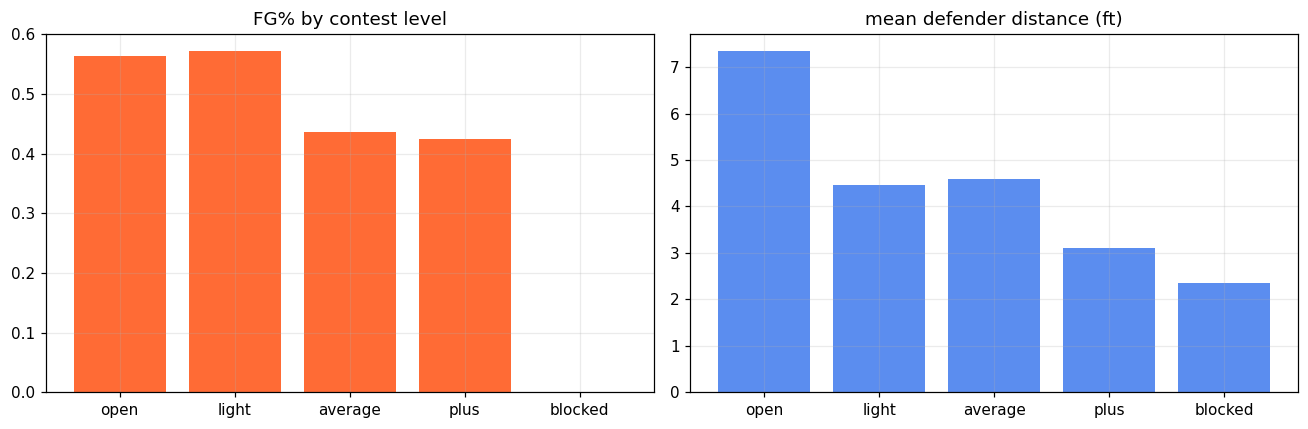

In [3]:
order = ["open","light","average","plus","blocked"]
g = (fga.groupby("contest_level").agg(n=("id","size"), fg=("outcome","mean"),
     def_dist=("closest_def_dist","mean"), sq=("shot_quality","mean")).reindex(order))
print(g.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(g.index, g.fg, color="#FF6B35"); ax[0].set_title("FG% by contest level")
ax[1].bar(g.index, g.def_dist, color="#5B8DEF"); ax[1].set_title("mean defender distance (ft)")
plt.tight_layout(); plt.show()

## The Simpson's paradox

Marginally, defender distance says nothing about whether a shot goes in. The confound is that the best shots are the most contested.

In [4]:
from scipy import stats
s1 = fga.dropna(subset=["closest_def_dist","dist_calc"])
t, p = stats.ttest_ind(s1.loc[s1.outcome,"closest_def_dist"],
                       s1.loc[~s1.outcome,"closest_def_dist"], equal_var=False)
print(f"MARGINAL  made {s1.loc[s1.outcome,'closest_def_dist'].mean():.2f} ft  "
      f"missed {s1.loc[~s1.outcome,'closest_def_dist'].mean():.2f} ft   t={t:+.2f}  p={p:.3f}")
print("\nthe confound:")
print(s1.groupby("zone_family").agg(n=("id","size"), fg=("outcome","mean"),
      def_dist=("closest_def_dist","mean")).round(3))
print("\nWITHIN STRATA:")
for z, g_ in s1.groupby("zone_family"):
    if len(g_) < 80: continue
    tt, pp = stats.ttest_ind(g_.loc[g_.outcome,"closest_def_dist"],
                             g_.loc[~g_.outcome,"closest_def_dist"], equal_var=False)
    print(f"  {z:22s} n={len(g_):4d}  made {g_.loc[g_.outcome,'closest_def_dist'].mean():.2f}  "
          f"miss {g_.loc[~g_.outcome,'closest_def_dist'].mean():.2f}  t={tt:+.2f}  p={pp:.4f}")

MARGINAL  made 4.43 ft  missed 4.61 ft   t=-1.02  p=0.308

the confound:
                        n     fg  def_dist
zone_family                               
above_break_3         403  0.347     5.912
corner_3               96  0.344     6.853
long_midrange         153  0.373     4.273
other                  14  0.071    15.430
rim                   340  0.629     3.162
short_midrange_paint  316  0.481     3.167

WITHIN STRATA:
  above_break_3          n= 403  made 5.87  miss 5.94  t=-0.22  p=0.8272
  corner_3               n=  96  made 8.20  miss 6.15  t=+2.75  p=0.0085
  long_midrange          n= 153  made 4.61  miss 4.07  t=+1.51  p=0.1342
  rim                    n= 340  made 3.57  miss 2.47  t=+5.35  p=0.0000
  short_midrange_paint   n= 316  made 3.41  miss 2.94  t=+2.28  p=0.0236


In [5]:
import statsmodels.api as sm_
X = sm_.add_constant(s1[["closest_def_dist","dist_calc"]].assign(three=s1.three.astype(int)))
fit = sm_.Logit(s1.outcome.astype(int), X).fit(disp=0)
print(fit.summary2().tables[1].round(4))
print(f"\nodds ratio per extra foot of separation: {np.exp(fit.params['closest_def_dist']):.3f}")

                   Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
const             0.3993    0.1216  3.2825  0.0010  0.1609  0.6377
closest_def_dist  0.1020    0.0231  4.4230  0.0000  0.0568  0.1472
dist_calc        -0.0940    0.0130 -7.2511  0.0000 -0.1194 -0.0686
three             0.5626    0.2459  2.2877  0.0222  0.0806  1.0446

odds ratio per extra foot of separation: 1.107


## The xFG model: performance and calibration

                          n  base_rate  log_loss  log_loss_baseline   brier  brier_baseline     auc
logistic+spatial     1322.0     0.4516    0.6228             0.6885  0.2176          0.2477  0.6895
logistic_no_spatial  1322.0     0.4516    0.6239             0.6885  0.2181          0.2477  0.6874
gbm                  1322.0     0.4516    0.6479             0.6885  0.2285          0.2477  0.6583

SkillCorner shotQuality AUC: 0.711  (correlation with ours 0.677)


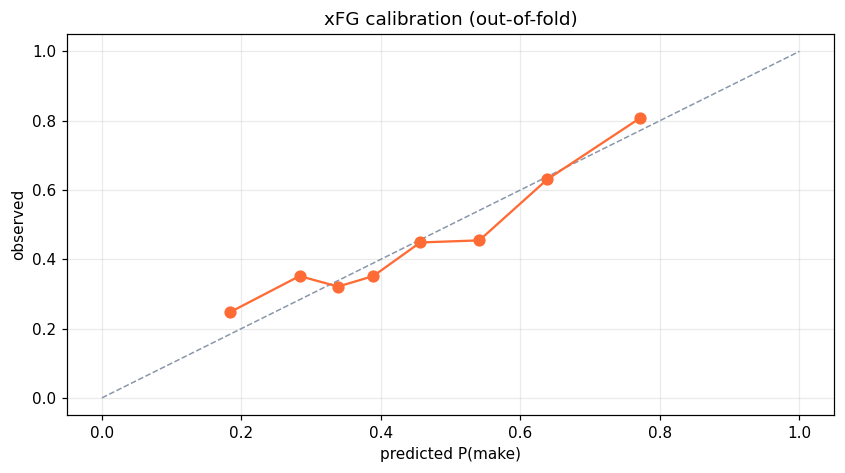

,bin,n,pred,actual,gap
0,"(0.021599999999999998, 0.252]",166,0.183,0.247,0.064
1,"(0.252, 0.31]",165,0.283,0.352,0.068
2,"(0.31, 0.365]",165,0.339,0.321,-0.017
3,"(0.365, 0.416]",165,0.389,0.352,-0.038
4,"(0.416, 0.498]",165,0.456,0.448,-0.008
5,"(0.498, 0.586]",165,0.541,0.455,-0.086
6,"(0.586, 0.695]",165,0.638,0.630,-0.008
7,"(0.695, 0.996]",166,0.771,0.807,0.036


In [6]:
import json
m = json.loads((D / "xfg_metrics.json").read_text())
print(pd.DataFrame({k: v for k, v in m.items() if isinstance(v, dict)}).T.round(4))
print(f"\nSkillCorner shotQuality AUC: {m['skillcorner_shotquality_auc']:.3f}"
      f"  (correlation with ours {m['skillcorner_vs_our_xfg_corr']:.3f})")
cal = rd("xfg_calibration")
plt.plot([0,1],[0,1],"--",color="#8A97AA",lw=1)
plt.plot(cal.pred, cal.actual, "o-", color="#FF6B35", ms=7)
plt.xlabel("predicted P(make)"); plt.ylabel("observed"); plt.title("xFG calibration (out-of-fold)")
plt.show(); cal.round(3)

## Shot creation

In [7]:
sh.groupby("creation_type").agg(n=("id","size"), fg=("outcome","mean"), xfg=("xfg","mean"),
   sq=("shot_quality","mean"), pts=("points","mean"), three=("three","mean"),
   open_rate=("contested", lambda s: 1-s.mean()),
   def_dist=("closest_def_dist","mean")).sort_values("n", ascending=False).round(3)

,n,fg,xfg,sq,pts,three,open_rate,def_dist
creation_type,,,,,,,,
drive,424,0.410,0.471,41.122,0.868,0.111,0.219,3.514
unstructured,383,0.486,0.534,50.167,1.034,0.209,0.341,4.337
pick,319,0.404,0.429,42.183,1.006,0.614,0.284,4.836
closeout,134,0.358,0.377,39.633,0.993,0.784,0.328,6.279
off_ball_screen,76,0.329,0.375,38.536,0.829,0.579,0.213,4.684
handoff,54,0.352,0.369,37.658,0.926,0.685,0.283,4.789
post,37,0.432,0.448,44.147,0.946,0.162,0.250,2.884
isolation,32,0.281,0.294,33.151,0.750,0.625,0.067,3.941
